# 第四课：相关性与等风险贡献配置

第三课发现：反波动率配置中，黄金只占约 22% 的资金，却贡献约 60% 的估计组合风险。本课只改变权重求解方式，加入资产之间的相关性。

**你将学会**：区分资金等权、反波动率、等风险贡献；理解优化器的目标与验证；区分“满足模型目标”和“未来投资效果”。

保持不变：SPY / IEF / GLD、126 日样本协方差、月度调仓、共同起始日、交易与分红处理。新增方法称为 ERC（Equal Risk Contribution，等风险贡献），是风险预算的一种特例。它不是收益预测、最小波动率优化或完整的机构全天候策略。

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from market_data import load_snapshot
from portfolio import simulate,reconcile
from risk_models import inverse_vol_schedule,equal_risk_schedule,risk_contributions
SNAPSHOT = __import__('os').environ.get('MARKET_LAB_SNAPSHOT', '20261007T234808781424Z')
LOOKBACK=126
frames,manifest=load_snapshot(SNAPSHOT)
assert all(f.index.equals(frames['SPY'].index) for f in frames.values())
prices=pd.DataFrame({s:f['Adj Close'] for s,f in frames.items()})
OUT=ROOT/'reports'/('04_'+SNAPSHOT); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(11,4),'axes.grid':True,'grid.alpha':.2})
inv,inv_audit=inverse_vol_schedule(prices,LOOKBACK)
erc,erc_audit=equal_risk_schedule(prices,LOOKBACK)
assert inv.index.equals(erc.index)
START=erc.index[0]
print('固定教学快照：',SNAPSHOT,'；数据截至',prices.index[-1].date())
print('共同模拟区间：',START.date(),'至',prices.index[-1].date())
print('本课没有刷新行情，也不代表今天的交易建议。')

固定教学快照： 20261007T234808781424Z ；数据截至 2026-10-06
共同模拟区间： 2010-08-02 至 2026-10-06
本课没有刷新行情，也不代表今天的交易建议。


## 1. 想让什么相等？

| 方法 | 想保持相等的东西 | 是否使用相关性求权重 |
|---|---|---|
| 资金等权 | 各项资金比例 | 否 |
| 反波动率 | 资金权重 × 自身波动率 | 否 |
| 等风险贡献 | 各项对组合波动的贡献 | 是 |

设权重为 $w$，协方差为 $\Sigma$，组合方差为 $w^T\Sigma w$。第 $i$ 项的风险占比为：

$$q_i=\frac{w_i(\Sigma w)_i}{w^T\Sigma w}$$

三资产 ERC 的目标是 $q_1=q_2=q_3=1/3$，同时权重为正、总和为 1。

这里“风险”特指基于历史协方差估计的组合波动，不是最大回撤、亏损概率或资产类别的全部风险。三分之一也是人为选择的风险预算，类似之前的 60/40 是资金预算；它并非自然界规定的最优比例。

如果某项资产贡献过多风险，求解器会尝试调整权重；但一次调整会改变所有风险占比，因此需要反复计算，不能简单把权重乘以一个比例就结束。

## 2. 求解器在做什么？

为了获得稳定且可解释的解，我们求解正数向量 $x$：

$$\min_{x>0}\ \frac12 x^T\Sigma x-\sum_i b_i\log x_i,\qquad b_i=1/3$$

你暂时不必掌握优化推导。关键是最优条件满足 $x_i(\Sigma x)_i=b_i$；最后把 $x$ 除以总和变成资金权重，风险占比就等于预算 $b_i$。

代码使用**坐标下降**：一次更新一个分量，轮流重复。每轮检查实际风险占比，而不是只相信“优化成功”的状态。允许的最大占比误差为十亿分之一；无有效解、数据病态或未收敛都停止。

本课没有仓位上限。加上上限之后，精确的等风险贡献可能无法实现，需要重新定义目标，而不能把原来的解简单截断后仍叫精确 ERC。

首次决策日： 2010-07-30 ；执行日： 2010-08-02
同一历史窗口的相关系数：


,SPY,IEF,GLD
SPY,1.000,-0.696,0.109
IEF,-0.696,1.000,0.070
GLD,0.109,0.070,1.000


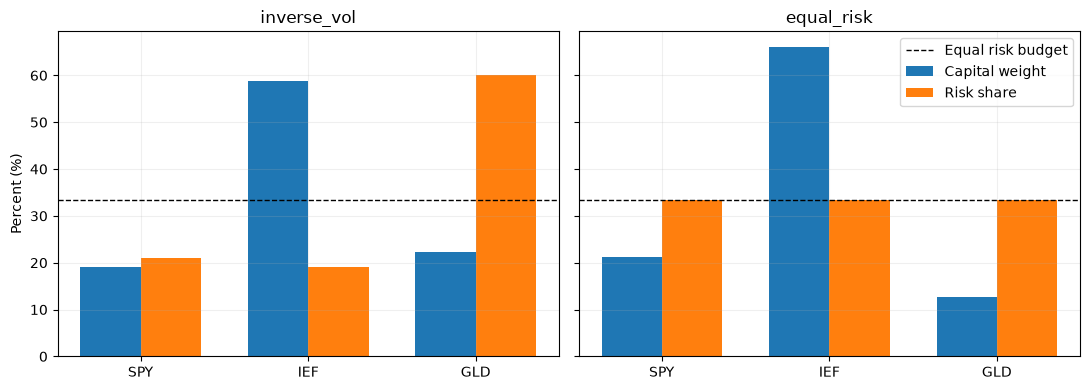

In [2]:
first_date=erc.index[0]
i=prices.index.get_loc(first_date)
cov=prices.pct_change(fill_method=None).iloc[i-LOOKBACK:i].cov()*252
vol=np.sqrt(np.diag(cov))
corr=cov/np.outer(vol,vol)
print('首次决策日：',erc.iloc[0].decision_date.date(),'；执行日：',first_date.date())
print('同一历史窗口的相关系数：')
display(corr.style.format('{:.3f}'))
first=pd.concat([inv_audit[(inv_audit.execution_date==first_date)&(inv_audit.policy=='inverse_vol')],
                 erc_audit[erc_audit.execution_date==first_date]])
display(first[['policy','asset','capital_weight','risk_share']].set_index(['policy','asset']).style.format('{:.2%}'))
fig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)
for ax,name in zip(axes,['inverse_vol','equal_risk']):
    a=first[first.policy==name].set_index('asset'); x=np.arange(len(a))
    ax.bar(x-.18,a.capital_weight*100,.36,label='Capital weight')
    ax.bar(x+.18,a.risk_share*100,.36,label='Risk share')
    ax.axhline(100/3,color='black',ls='--',lw=1,label='Equal risk budget')
    ax.set_xticks(x,a.index); ax.set_title(name)
axes[0].set_ylabel('Percent (%)'); axes[1].legend()
fig.tight_layout(); fig.savefig(OUT/'01_first_decision.png',dpi=150); plt.show()

## 3. 如何读首次决策？

左图是上节的反波动率配置，右图是使用同一个协方差估计求出的 ERC。右图橙色柱应该几乎一样高，蓝色柱不需要一样高。

前面的相关性表说明：当某些资产能相互抵消波动时，可以配置较多资金而不贡献同等比例的净风险；相对缺乏这种抵消效果的资产可能需要更少资金。不能仅凭某一个相关系数单独确定最终权重。

**模型风险**：这些相关性来自过去 126 日。市场关系改变后，未来实际风险不一定仍各占三分之一；开盘价格跳动、每日权重漂移也会改变风险。下面验证的是每次决策时的目标组合，不是未来实际持仓风险。

目标次数： 195 ；最大风险占比绝对误差： 9.827e-10
最大求解迭代轮数： 20


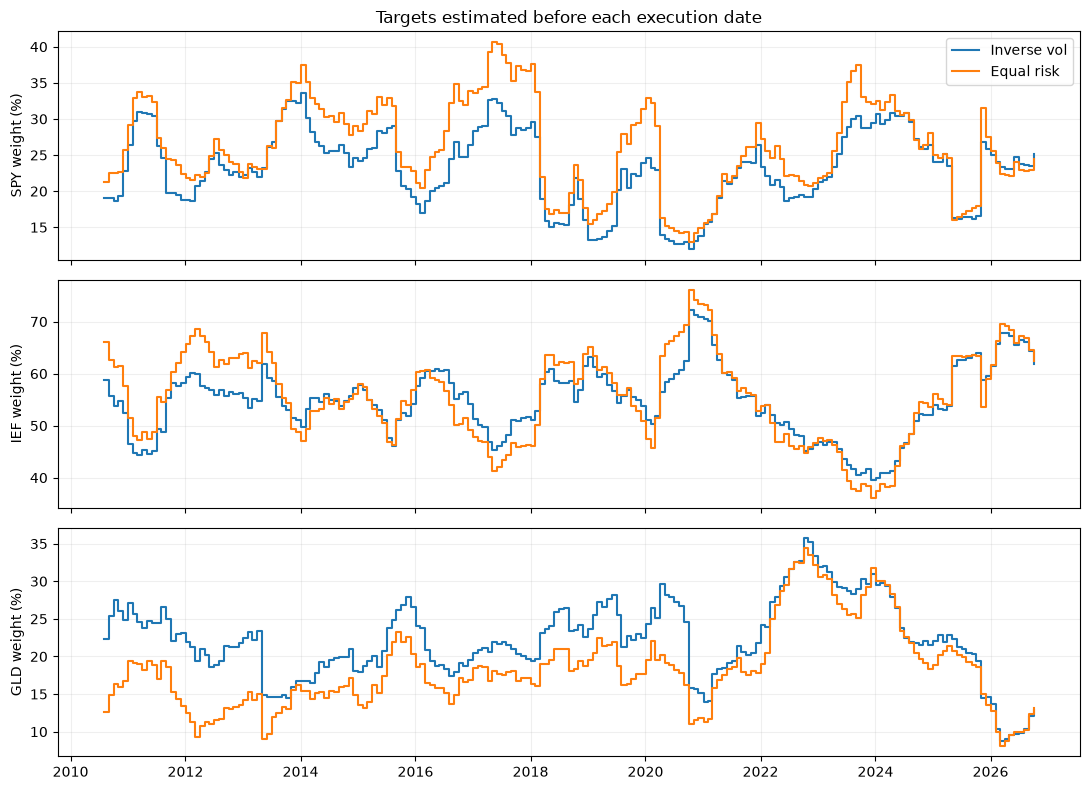

,SPY,IEF,GLD
min,12.90%,36.16%,8.10%
mean,26.08%,55.57%,18.34%
max,40.70%,76.07%,34.42%


上表均值是月度目标均值，不是每日持仓均值。


In [3]:
erc.to_csv(OUT/'erc_targets.csv'); inv.to_csv(OUT/'inverse_vol_targets.csv')
erc_audit.to_csv(OUT/'erc_risk_audit.csv',index=False)
inv_audit.to_csv(OUT/'baseline_risk_audit.csv',index=False)
error=(erc_audit.risk_share-1/3).abs().max()
print('目标次数：',len(erc),'；最大风险占比绝对误差：',f'{error:.3e}')
print('最大求解迭代轮数：',int(erc.iterations.max()))
assert error<1e-9
assert (erc.decision_date.to_numpy()<erc.index.to_numpy()).all()
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True)
for ax,s in zip(axes,prices.columns):
    ax.step(inv.index,inv[s]*100,where='post',label='Inverse vol')
    ax.step(erc.index,erc[s]*100,where='post',label='Equal risk')
    ax.set_ylabel(s+' weight (%)')
axes[0].legend(); axes[0].set_title('Targets estimated before each execution date')
fig.tight_layout(); fig.savefig(OUT/'02_weights.png',dpi=150); plt.show()
display(erc[list(prices.columns)].agg(['min','mean','max']).style.format('{:.2%}'))
print('上表均值是月度目标均值，不是每日持仓均值。')

## 4. 在相同条件下比较投资结果

全部使用同一初始本金 100,000 美元、月度开盘调仓、单边成本 5 bps（0.05%）、零碎份额、无杠杆、现金不计息、除息日立即计入分红的教学简化。所有组合在调仓时重新投入现金。

加入三资产等权和 60/40 作为参照，主要实验比较 ERC 与反波动率，二者仅改变配置方法。仍未匹配总风险，因此收益差不能直接视为 alpha。

执行仍是按开盘价精确计算份额并成交的理想化假设；没有模拟实际到账、资金结算、成交队列、税费和大额市场冲击。拆股或资本利得分配等未支持事件会报错。

,final_nav,cagr,annual_volatility,max_drawdown,fees_paid
60_40,"450,387.42",9.75%,9.74%,-21.20%,440.13
equal_3,"374,369.24",8.50%,8.52%,-17.01%,481.37
inverse_vol,"269,694.34",6.32%,6.51%,-17.33%,706.18
equal_risk,"273,415.49",6.41%,6.35%,-17.89%,823.98


列依次为：期末资产、年化收益、年化波动、最大回撤、累计费用。


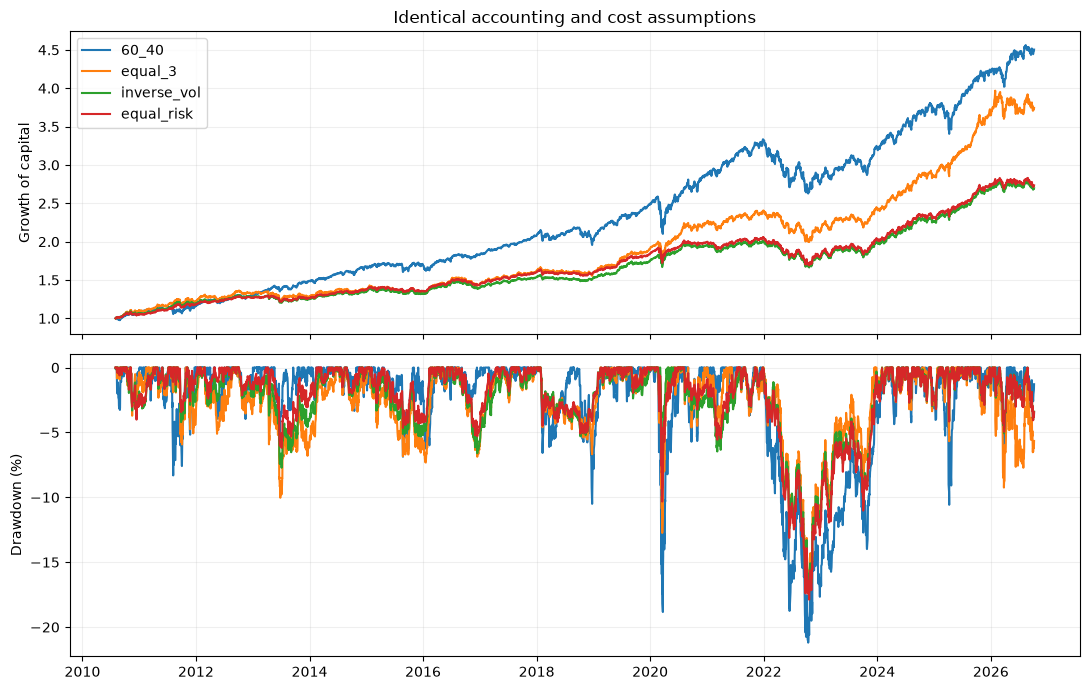

相对反波动率，ERC 年化收益相差 **+0.09 个百分点**，波动相差 **-0.16 个百分点**，最大回撤分别为 **-17.89% / -17.33%**。满足等风险目标不自动意味着收益更高或回撤更小。

In [4]:
trading={s:f.loc[START:].copy() for s,f in frames.items()}
policies={'60_40':{'SPY':.6,'IEF':.4},'equal_3':dict.fromkeys(prices.columns,1/3),
          'inverse_vol':inv.iloc[0][list(prices.columns)].to_dict(),
          'equal_risk':erc.iloc[0][list(prices.columns)].to_dict()}
schedules={'inverse_vol':inv,'equal_risk':erc}
results={name:simulate(trading,w,target_schedule=schedules.get(name)) for name,w in policies.items()}
for name,r in results.items():
    r.daily.to_csv(OUT/(name+'_daily.csv'))
    r.trades.to_csv(OUT/(name+'_trades.csv'),index=False)
    r.distributions.to_csv(OUT/(name+'_distributions.csv'),index=False)
metrics=pd.DataFrame({name:r.metrics() for name,r in results.items()}).T
metrics.to_csv(OUT/'metrics.csv')
display(metrics[['final_nav','cagr','annual_volatility','max_drawdown','fees_paid']].style.format({
    'final_nav':'{:,.2f}','cagr':'{:.2%}','annual_volatility':'{:.2%}','max_drawdown':'{:.2%}','fees_paid':'{:,.2f}'}))
print('列依次为：期末资产、年化收益、年化波动、最大回撤、累计费用。')
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for name,r in results.items():
    nav=r.daily.nav; peak=np.maximum.accumulate(np.r_[100000,nav.to_numpy()])[1:]
    axes[0].plot(nav.index,nav/100000,label=name)
    axes[1].plot(nav.index,(nav/peak-1)*100,label=name)
axes[0].set(ylabel='Growth of capital',title='Identical accounting and cost assumptions')
axes[0].legend(); axes[1].set_ylabel('Drawdown (%)')
fig.tight_layout(); fig.savefig(OUT/'03_performance.png',dpi=150); plt.show()
a,b=metrics.loc['equal_risk'],metrics.loc['inverse_vol']
display(Markdown(f'相对反波动率，ERC 年化收益相差 **{100*(a.cagr-b.cagr):+.2f} 个百分点**，波动相差 **{100*(a.annual_volatility-b.annual_volatility):+.2f} 个百分点**，最大回撤分别为 **{a.max_drawdown:.2%} / {b.max_drawdown:.2%}**。满足等风险目标不自动意味着收益更高或回撤更小。'))

## 5. 验证、局限与现实意义

数学验证与投资验证分开：前者检查风险贡献是否确实相等；后者观察不同市场下的成本、收益和风险，还需要未来数据持续检验。

测试包括：互不相关资产的 ERC 应等于反波动率；相关资产的手算解；协方差整体缩放、资产排序不应改变经济含义；无效输入与不收敛必须拒绝；修改执行日及之后价格不应改变此前目标。交易账本继续独立核对。

实际业务用途是执行明确的风险预算、识别过度集中、生成可追溯的配置方案。它不自动给出适合个人的投资计划，也没有解决利率、通胀或尾部风险等全部问题。

仍使用已观察过的历史和可能修订的数据，不是严格未接触的样本外证据。本课不搜索窗口、不加杠杆，也没有设总波动目标。

In [5]:
checks=pd.DataFrame({name:reconcile(r) for name,r in results.items()}).T.fillna(0)
checks.to_csv(OUT/'reconciliation.csv'); display(checks)
assert checks.to_numpy().max()<1e-6
# Confirm unchanged baselines against the previously executed lesson.
previous=pd.read_csv(ROOT/'reports'/('03_'+SNAPSHOT)/'metrics.csv',index_col=0)
np.testing.assert_allclose(metrics.loc[previous.index,previous.columns],previous,rtol=1e-10,atol=1e-7)
print('第四课三个原有基准与第三课一致；四个账本对账通过。')
settings=dict(snapshot=SNAPSHOT,lookback=LOOKBACK,start=str(START.date()),end=str(prices.index[-1].date()),
    initial_cash=100000,cost_bps=5,risk_budget=[1/3]*3,solver='cyclic coordinate descent',
    tolerance=1e-9,max_iterations=10000,max_observed_error=float(error),
    model='sample covariance of prior adjusted returns, annualized by 252',
    limitations=['ex-date immediate cash','idealized open execution','no taxes','no position cap','no leverage'],
    source_manifest=manifest,code_sha256={s:hashlib.sha256((ROOT/s).read_bytes()).hexdigest()
    for s in ['src/risk_models.py','src/portfolio.py','src/market_data.py']})
(OUT/'run_manifest.json').write_text(json.dumps(settings,indent=2),encoding='utf-8')

,cash_error,SPY_shares_error,IEF_shares_error,nav_error,GLD_shares_error
60_40,4.307367e-09,0.0,0.0,5.820766e-11,0.0
equal_3,2.604793e-09,0.0,0.0,0.000000e+00,0.0
inverse_vol,3.070454e-09,0.0,0.0,0.000000e+00,0.0
equal_risk,3.215973e-09,0.0,0.0,0.000000e+00,0.0


第四课三个原有基准与第三课一致；四个账本对账通过。


1718

## 6. 本节练习与下一步

先回答：

1. 三项资产风险各占三分之一，是否意味着资金也各占三分之一？
2. 过去数据算出的风险占比准确达到目标，能否保证下个月仍然如此？
3. 如果要求债券资金权重最多 40%，而无约束 ERC 希望配得更多，能否直接截断后仍宣称风险严格相等？

答案分别为：不能；不能；不能。第三个问题需要定义约束下的折中目标，并重新检查风险贡献。

本节新增的是利用相关性的风险预算配置。下一步可以研究仓位约束或风险估计稳定性；之后再单独加入趋势收益信号，检验在既有风险配置之上是否增加价值。我们不会因为新方法历史收益较高就立即将它视为实盘方案。